# Fig. 2: numerical verification of the response identity (Eq. 3) and of the bound (Eq. 9)

(a) Scaling factor versus the normalized nonlinear response for B-, A- and E-type perturbations of a random five-state network. (b) Nonlinear-to-linear response ratio for fully connected five-state networks with random rates and observables.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join('..', 'lib')))
OUT = os.path.abspath(os.path.join('..', 'figures'))
os.makedirs(OUT, exist_ok=True)

import numpy as np
np.random.seed(2026)

## Model and helper functions

In [2]:
from ftMarkov import *
import matplotlib.pyplot as plt
import numpy as np

def generate_matrix(E,B,F):
    size = np.shape(E)[0]
    # Compute rates
    W = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            if i != j:
                W[i,j] = np.exp(-(B[i,j] - E[j] - F[i,j]/2))
    W = W - np.diag(W.sum(axis=0))
    return W

def generate_random_network(size, scale=12.0,seed=None):
    if seed is not None:
        np.random.seed(seed)
    """Generate random network parameters and transition rates"""
    # Generate parameters
    E = (np.random.rand(size)-0.5)*scale
    B = (np.random.rand(size, size)-0.5)*scale
    B = (B + B.T) / 2  # symmetric
    F = (np.random.rand(size,size)-0.5)*scale
    F = (F - F.T) / 2  # antisymmetric
    W = generate_matrix(E,B,F)
    return W, E, B, F

def compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable, response_fn,return_linear_response=False):
    """Compute response for a single edge over different perturbation strengths, using a user-specified response function"""
    # = MarkovNet(W)
    markov = MarkovNet( generate_matrix(E, B, F))
    #markov_small = W_small)
    original_pss = markov.pss
    # if postive:
    #     observable = np.random.randn(len(W))#np.exp(-8*np.random.randn(len(W)))#np.random.randn(len(W))
    # else:
    #     observable = #(np.random.randn(len(W)) - 0.5)
    original_obs = np.sum(observable * original_pss)
    original_obs_sq = np.sum((observable**2) * original_pss)
    original_variance = original_obs_sq - original_obs**2
    # First compute linear response (eps->0 limit)
    eps_small = 1e-4
    E_small, B_small, F_small = E.copy(), B.copy(), F.copy()
    
    if perturb_type == 'B':
        B_small[m,n] += eps_small
        B_small[n,m] += eps_small
    elif perturb_type == 'F':
        F_small[m,n] += eps_small
        F_small[n,m] -= eps_small
    elif perturb_type == 'E':
        E_small[m] += eps_small
    elif perturb_type == 'A':
        # For A perturbation, we directly perturb the A matrix element
        # A[i,j] = B[i,j] - E[j] - F[i,j]/2
        # So perturbing A[m,n] by eps_small is equivalent to perturbing B[m,n] by eps_small
        B_small[m,n] += eps_small
        
    W_small = generate_matrix(E_small, B_small, F_small)
    markov_small = MarkovNet(W_small)
    new_obs_small = np.sum(observable * markov_small.pss)
    linear_response = (new_obs_small - original_obs) / eps_small
    
    responses = []
    for eps in eps_range:
        E_new, B_new, F_new = E.copy(), B.copy(), F.copy()
        if perturb_type == 'B':
            B_new[m,n] += eps
            B_new[n,m] += eps
        elif perturb_type == 'F':
            F_new[m,n] += eps
            F_new[n,m] -= eps
        elif perturb_type == 'E':
            E_new[m] += eps
        elif perturb_type == 'A':
            # For A perturbation, we directly perturb the A matrix element
            # A[i,j] = B[i,j] - E[j] - F[i,j]/2
            # So perturbing A[m,n] by eps is equivalent to perturbing B[m,n] by eps
            B_new[m,n] += eps
        
        W_new = generate_matrix(E_new, B_new, F_new)
        markov_new = MarkovNet(W_new)
        new_pss = markov_new.pss
        new_obs = np.sum(observable * new_pss)
        # Calculate variance in perturbed case
        new_obs_sq = np.sum((observable**2) * new_pss)
        new_variance = new_obs_sq - new_obs**2
        
        # compute the response with the user-supplied function
        response = response_fn(original_obs, new_obs, eps,linear_response, original_variance, new_variance)
        responses.append(response)
    if return_linear_response:
        return responses, linear_response
    else:
        return responses


def plot_results(all_responses, eps_range, perturb_type):
    """Create plot of responses vs perturbation strength"""
    # Define colors for different perturbation types
    colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}
    # Plot response for each network
    for i, responses in enumerate(all_responses):
        plt.plot(eps_range, responses, '-',
                alpha=0.2, color=colors[perturb_type])
    
    #plt.xlabel(f'Perturbation Strength ($\Delta {perturb_type}$)')
    #plt.ylabel(r'Current Response / Linear Response, $\frac{\Delta J_{mn}}{e^{\Delta F_e}-1}\left(\partial_{F_e}J_{mn}\right)^{-1}$')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    return plt.gcf()


## Fig. 2(a), B-type perturbation

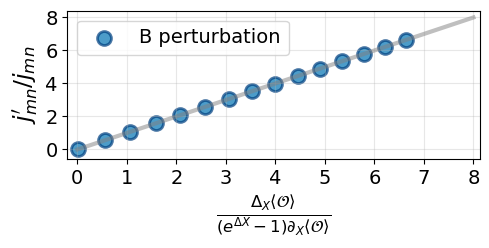

In [3]:
# Define response function to compute the change in observable and Rx ratios
def compute_response_with_ratios(E, B, F, m, n, eps_values, perturb_type, observable):
    responses = []
    rx_values = []
    
    # Compute original steady state
    W_original = generate_matrix(E, B, F)
    markov_original = MarkovNet(W_original)
    pi_original = markov_original.pss
    original_obs = np.dot(observable, pi_original)
    
    # Compute linear response (derivative)
    if perturb_type == 'E':
        # Energy perturbation
        E_pert = E.copy()
        E_pert[m] += 1e-8
        W_pert = generate_matrix(E_pert, B, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    elif perturb_type == 'B':
        # Barrier perturbation
        B_pert = B.copy()
        B_pert[m, n] += 1e-8
        B_pert[n, m] += 1e-8
        W_pert = generate_matrix(E, B_pert, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    elif perturb_type == 'A':
        # Activity perturbation
        B_pert = B.copy()
        B_pert[m, n] += 1e-8
        W_pert = generate_matrix(E, B_pert, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    
    for eps in eps_values:
        if perturb_type == 'E':
            # Energy perturbation
            E_new = E.copy()
            E_new[m] += eps
            W_new = generate_matrix(E_new, B, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = pi_m' / pi_m
            rx = pi_new[m] / pi_original[m]
            
        elif perturb_type == 'B':
            # Barrier perturbation
            B_new = B.copy()
            B_new[m, n] += eps
            B_new[n, m] += eps
            W_new = generate_matrix(E, B_new, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = j_mn' / j_mn (current ratio)
            # j_original = pi_original[m] * W_original[n,m]-pi_original[n] * W_original[m,n]
            # j_new = pi_new[m] * W_new[n,m]-pi_new[n] * W_new[m,n]
            j_original = markov_original.J(m,n)
            j_new = markov_new.J(m,n)
            rx = j_new / j_original #if j_original != 0 else 1.0
            
        elif perturb_type == 'A':
            # Activation Energy perturbation
            B_new = B.copy()
            B_new[m, n] += eps
            W_new = generate_matrix(E, B_new, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = pi_n' / pi_n
            rx = W_new[m,n] * pi_new[n] / (W_original[m,n] * pi_original[n])
            #rx = pi_new[n] / pi_original[n]
        
        # Compute normalized response
        
        response = (new_obs - original_obs) / linear_response / (np.exp(eps) - 1)
            
        responses.append(response)
        rx_values.append(rx)
    
    return np.array(responses), np.array(rx_values)
eps_range = -np.log(np.linspace(np.exp(-4),np.exp(2),15))#
#eps_range = np.linspace(-2,4, 20)  
# Compute responses and Rx values for all perturbation types
perturb_types = ['A', 'B', 'E']

colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}
# Set darker colors for marker edges
edge_colors = {'B': '#004080', 'F': '#0f4d7a', 'E': '#A04000', 'A': '#006B4F'}

markers = {'B': 'o', 'E': 's', 'A': '^'}

all_responses = {}
all_rx_values = {}
seed=40
np.random.seed(seed)
W, E, B, F = generate_random_network(5,scale=10,seed=seed)

m, n = 0, 1
observable = (np.random.randn(len(W)) - 0.5)*2
for perturb_type in perturb_types:
    responses, rx_values = compute_response_with_ratios( E, B, F, m, n, eps_range, perturb_type, observable)
    all_responses[perturb_type] = responses
    all_rx_values[perturb_type] = rx_values

# Create the plot
plt.figure(figsize=(5, 5))

# Plot the line first (so it appears below the scatter points)
#plt.plot(np.exp(-eps_range),np.exp(-eps_range),linewidth=3,c='gray',alpha=.5)
plt.plot(np.linspace(0,8,100),np.linspace(0,8,100),linewidth=3,c='gray',alpha=.5)
perturb_types = ['B']
for perturb_type in perturb_types:
    #plt.plot(all_responses[perturb_type], all_rx_values[perturb_type],linewidth=2,c)
    observable = (np.random.randn(len(W)) - 0.5)*2
    plt.scatter( all_rx_values[perturb_type], all_responses[perturb_type],
               color=colors[perturb_type], alpha=.7, s=100, label=f'{perturb_type} perturbation',
               edgecolors=edge_colors[perturb_type], linewidth=2, marker=markers[perturb_type])
#plt.ylabel(r'$R^x$', fontsize=17)
    ylabels = {'B': r'$j_{mn}^{\prime}/j_{mn}$', 'E': r'$\pi_{m}^{\prime}/\pi_{m}$', 'A': r'$\phi_{mn}^{\prime}/\phi_{mn}$'}
    plt.ylabel(ylabels[perturb_type], fontsize=17)
#plt.ylabel(r'$\phi_{mn}^{\prime}/\phi_{mn}$', fontsize=17)
plt.xlabel(r'$\frac{\Delta_X \langle \mathcal{O}\rangle}{(e^{\Delta X}-1)\partial_{X}\langle \mathcal{O}\rangle} $', fontsize=17)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlim(-.2,8.13)
plt.ylim(-.6,8.4)
plt.grid(True, alpha=0.3)
plt.gca().set_aspect(1/3, adjustable='box')
plt.savefig(os.path.join(OUT, 'Fig2a_identity_B.svg'),bbox_inches='tight')
plt.tight_layout()
plt.show()


## Fig. 2(a), A-type perturbation

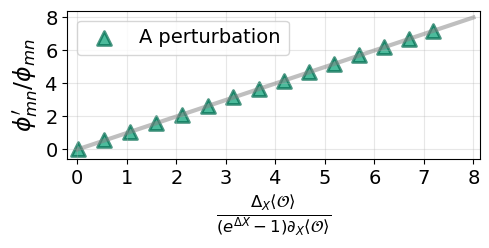

In [4]:
# Define response function to compute the change in observable and Rx ratios
def compute_response_with_ratios(E, B, F, m, n, eps_values, perturb_type, observable):
    responses = []
    rx_values = []
    
    # Compute original steady state
    W_original = generate_matrix(E, B, F)
    markov_original = MarkovNet(W_original)
    pi_original = markov_original.pss
    original_obs = np.dot(observable, pi_original)
    
    # Compute linear response (derivative)
    if perturb_type == 'E':
        # Energy perturbation
        E_pert = E.copy()
        E_pert[m] += 1e-8
        W_pert = generate_matrix(E_pert, B, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    elif perturb_type == 'B':
        # Barrier perturbation
        B_pert = B.copy()
        B_pert[m, n] += 1e-8
        B_pert[n, m] += 1e-8
        W_pert = generate_matrix(E, B_pert, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    elif perturb_type == 'A':
        # Activity perturbation
        B_pert = B.copy()
        B_pert[m, n] += 1e-8
        W_pert = generate_matrix(E, B_pert, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    
    for eps in eps_values:
        if perturb_type == 'E':
            # Energy perturbation
            E_new = E.copy()
            E_new[m] += eps
            W_new = generate_matrix(E_new, B, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = pi_m' / pi_m
            rx = pi_new[m] / pi_original[m]
            
        elif perturb_type == 'B':
            # Barrier perturbation
            B_new = B.copy()
            B_new[m, n] += eps
            B_new[n, m] += eps
            W_new = generate_matrix(E, B_new, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = j_mn' / j_mn (current ratio)
            # j_original = pi_original[m] * W_original[n,m]-pi_original[n] * W_original[m,n]
            # j_new = pi_new[m] * W_new[n,m]-pi_new[n] * W_new[m,n]
            j_original = markov_original.J(m,n)
            j_new = markov_new.J(m,n)
            rx = j_new / j_original #if j_original != 0 else 1.0
            
        elif perturb_type == 'A':
            # Activation Energy perturbation
            B_new = B.copy()
            B_new[m, n] += eps
            W_new = generate_matrix(E, B_new, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = pi_n' / pi_n
            rx = W_new[m,n] * pi_new[n] / (W_original[m,n] * pi_original[n])
            #rx = pi_new[n] / pi_original[n]
        
        # Compute normalized response
        
        response = (new_obs - original_obs) / linear_response / (np.exp(eps) - 1)
            
        responses.append(response)
        rx_values.append(rx)
    
    return np.array(responses), np.array(rx_values)
eps_range = -np.log(np.linspace(np.exp(-4),np.exp(2),15))#
#eps_range = np.linspace(-2,4, 20)  
# Compute responses and Rx values for all perturbation types
perturb_types = ['A', 'B', 'E']

colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}
# Set darker colors for marker edges
edge_colors = {'B': '#004080', 'F': '#0f4d7a', 'E': '#A04000', 'A': '#006B4F'}

markers = {'B': 'o', 'E': 's', 'A': '^'}

all_responses = {}
all_rx_values = {}
seed=40
np.random.seed(seed)
W, E, B, F = generate_random_network(5,scale=10,seed=seed)

m, n = 0, 1
observable = (np.random.randn(len(W)) - 0.5)*2
for perturb_type in perturb_types:
    responses, rx_values = compute_response_with_ratios( E, B, F, m, n, eps_range, perturb_type, observable)
    all_responses[perturb_type] = responses
    all_rx_values[perturb_type] = rx_values

# Create the plot
plt.figure(figsize=(5, 5))

# Plot the line first (so it appears below the scatter points)
#plt.plot(np.exp(-eps_range),np.exp(-eps_range),linewidth=3,c='gray',alpha=.5)
plt.plot(np.linspace(0,8,100),np.linspace(0,8,100),linewidth=3,c='gray',alpha=.5)
perturb_types = ['A']
for perturb_type in perturb_types:
    #plt.plot(all_responses[perturb_type], all_rx_values[perturb_type],linewidth=2,c)
    observable = (np.random.randn(len(W)) - 0.5)*2
    plt.scatter( all_rx_values[perturb_type], all_responses[perturb_type],
               color=colors[perturb_type], alpha=.7, s=100, label=f'{perturb_type} perturbation',
               edgecolors=edge_colors[perturb_type], linewidth=2, marker=markers[perturb_type])
#plt.ylabel(r'$R^x$', fontsize=17)
    ylabels = {'B': r'$j_{mn}^{\prime}/j_{mn}$', 'E': r'$\pi_{m}^{\prime}/\pi_{m}$', 'A': r'$\phi_{mn}^{\prime}/\phi_{mn}$'}
    plt.ylabel(ylabels[perturb_type], fontsize=17)
#plt.ylabel(r'$\phi_{mn}^{\prime}/\phi_{mn}$', fontsize=17)
plt.xlabel(r'$\frac{\Delta_X \langle \mathcal{O}\rangle}{(e^{\Delta X}-1)\partial_{X}\langle \mathcal{O}\rangle} $', fontsize=17)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlim(-.2,8.13)
plt.ylim(-.6,8.4)
plt.grid(True, alpha=0.3)
plt.gca().set_aspect(1/3, adjustable='box')
plt.savefig(os.path.join(OUT, 'Fig2a_identity_A.svg'),bbox_inches='tight')
plt.tight_layout()
plt.show()


## Fig. 2(a), E-type perturbation

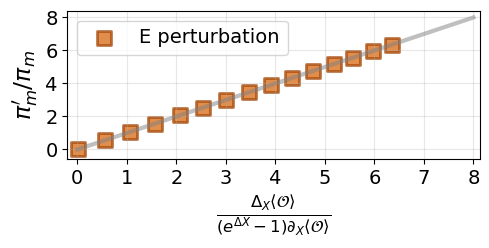

In [5]:
# Define response function to compute the change in observable and Rx ratios
def compute_response_with_ratios(E, B, F, m, n, eps_values, perturb_type, observable):
    responses = []
    rx_values = []
    
    # Compute original steady state
    W_original = generate_matrix(E, B, F)
    markov_original = MarkovNet(W_original)
    pi_original = markov_original.pss
    original_obs = np.dot(observable, pi_original)
    
    # Compute linear response (derivative)
    if perturb_type == 'E':
        # Energy perturbation
        E_pert = E.copy()
        E_pert[m] += 1e-8
        W_pert = generate_matrix(E_pert, B, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    elif perturb_type == 'B':
        # Barrier perturbation
        B_pert = B.copy()
        B_pert[m, n] += 1e-8
        B_pert[n, m] += 1e-8
        W_pert = generate_matrix(E, B_pert, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    elif perturb_type == 'A':
        # Activity perturbation
        B_pert = B.copy()
        B_pert[m, n] += 1e-8
        W_pert = generate_matrix(E, B_pert, F)
        markov_pert = MarkovNet(W_pert)
        pi_pert = markov_pert.pss
        obs_pert = np.dot(observable, pi_pert)
        linear_response = (obs_pert - original_obs) / 1e-8
    
    for eps in eps_values:
        if perturb_type == 'E':
            # Energy perturbation
            E_new = E.copy()
            E_new[m] += eps
            W_new = generate_matrix(E_new, B, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = pi_m' / pi_m
            rx = pi_new[m] / pi_original[m]
            
        elif perturb_type == 'B':
            # Barrier perturbation
            B_new = B.copy()
            B_new[m, n] += eps
            B_new[n, m] += eps
            W_new = generate_matrix(E, B_new, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = j_mn' / j_mn (current ratio)
            # j_original = pi_original[m] * W_original[n,m]-pi_original[n] * W_original[m,n]
            # j_new = pi_new[m] * W_new[n,m]-pi_new[n] * W_new[m,n]
            j_original = markov_original.J(m,n)
            j_new = markov_new.J(m,n)
            rx = j_new / j_original #if j_original != 0 else 1.0
            
        elif perturb_type == 'A':
            # Activation Energy perturbation
            B_new = B.copy()
            B_new[m, n] += eps
            W_new = generate_matrix(E, B_new, F)
            markov_new = MarkovNet(W_new)
            pi_new = markov_new.pss
            new_obs = np.dot(observable, pi_new)
            
            # Compute Rx = pi_n' / pi_n
            rx = W_new[m,n] * pi_new[n] / (W_original[m,n] * pi_original[n])
            #rx = pi_new[n] / pi_original[n]
        
        # Compute normalized response
        
        response = (new_obs - original_obs) / linear_response / (np.exp(eps) - 1)
            
        responses.append(response)
        rx_values.append(rx)
    
    return np.array(responses), np.array(rx_values)
eps_range = -np.log(np.linspace(np.exp(-4),np.exp(2),15))#
#eps_range = np.linspace(-2,4, 20)  
# Compute responses and Rx values for all perturbation types
perturb_types = ['A', 'B', 'E']

colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}
# Set darker colors for marker edges
edge_colors = {'B': '#004080', 'F': '#0f4d7a', 'E': '#A04000', 'A': '#006B4F'}

markers = {'B': 'o', 'E': 's', 'A': '^'}

all_responses = {}
all_rx_values = {}
seed=40
np.random.seed(seed)
W, E, B, F = generate_random_network(5,scale=10,seed=seed)

m, n = 0, 1
observable = (np.random.randn(len(W)) - 0.5)*2
for perturb_type in perturb_types:
    responses, rx_values = compute_response_with_ratios( E, B, F, m, n, eps_range, perturb_type, observable)
    all_responses[perturb_type] = responses
    all_rx_values[perturb_type] = rx_values

# Create the plot
plt.figure(figsize=(5, 5))

# Plot the line first (so it appears below the scatter points)
#plt.plot(np.exp(-eps_range),np.exp(-eps_range),linewidth=3,c='gray',alpha=.5)
plt.plot(np.linspace(0,8,100),np.linspace(0,8,100),linewidth=3,c='gray',alpha=.5)
perturb_types = ['E']
for perturb_type in perturb_types:
    #plt.plot(all_responses[perturb_type], all_rx_values[perturb_type],linewidth=2,c)
    observable = (np.random.randn(len(W)) - 0.5)*2
    plt.scatter( all_rx_values[perturb_type], all_responses[perturb_type],
               color=colors[perturb_type], alpha=.7, s=100, label=f'{perturb_type} perturbation',
               edgecolors=edge_colors[perturb_type], linewidth=2, marker=markers[perturb_type])
#plt.ylabel(r'$R^x$', fontsize=17)
    ylabels = {'B': r'$j_{mn}^{\prime}/j_{mn}$', 'E': r'$\pi_{m}^{\prime}/\pi_{m}$', 'A': r'$\phi_{mn}^{\prime}/\phi_{mn}$'}
    plt.ylabel(ylabels[perturb_type], fontsize=17)
#plt.ylabel(r'$\phi_{mn}^{\prime}/\phi_{mn}$', fontsize=17)
plt.xlabel(r'$\frac{\Delta_X \langle \mathcal{O}\rangle}{(e^{\Delta X}-1)\partial_{X}\langle \mathcal{O}\rangle} $', fontsize=17)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlim(-.2,8.13)
plt.ylim(-.6,8.4)
plt.grid(True, alpha=0.3)
plt.gca().set_aspect(1/3, adjustable='box')
plt.savefig(os.path.join(OUT, 'Fig2a_identity_E.svg'),bbox_inches='tight')
plt.tight_layout()
plt.show()


## Fig. 2(b)

Computing responses for 100 networks...
Network 0/100
Network 10/100


Network 20/100
Network 30/100


Network 40/100
Network 50/100


Network 60/100
Network 70/100


Network 80/100
Network 90/100


Creating plot...


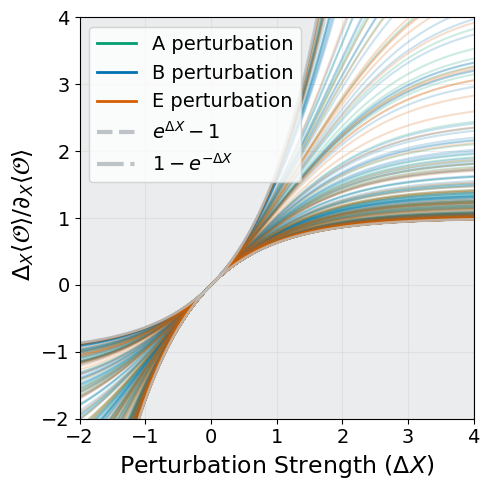

In [6]:
def response_fn(original_obs, new_obs, eps, linear_response, original_variance,new_variance):
    return  (new_obs - original_obs)  / linear_response

# Parameters
SIZE = 5
N_NETWORKS = 100  # Number of different networks to generate
eps_range = np.linspace(-2, 4, 100)

# List of perturbation types to try in random order
perturb_types = ['A', 'B', 'E']
#perturb_types = ['E']
#np.random.shuffle(perturb_types)

# Dictionary to store responses for each type
all_responses_dict = {ptype: [] for ptype in perturb_types}

# Colors for each perturbation type
colors = {'B': '#0072B2', 'F': '#1f77b4', 'E': '#D55E00', 'A': '#009E73'}

print(f"Computing responses for {N_NETWORKS} networks...")
for i in range(N_NETWORKS):
    if i % 10 == 0:
        print(f"Network {i}/{N_NETWORKS}")
        
    # Generate random network
    W, E, B, F = generate_random_network(SIZE,scale=10)
    
    # Choose random edge to perturb
    while True:
        m = np.random.randint(0, SIZE)
        n = np.random.randint(0, SIZE)
        if m != n and W[m,n] != 0 and W[n,m] != 0:
            break
            
    # Compute responses for each perturbation type
    for perturb_type in perturb_types:
        observable = (np.random.randn(len(W)) - 0.5)*2
        responses = compute_single_edge_response(W, E, B, F, m, n, eps_range, perturb_type,observable,response_fn)
        all_responses_dict[perturb_type].append(responses)


bound_color = '#BDC3C7'      # Light gray

# Plot results for each perturbation type
print("Creating plot...")
plt.figure(figsize=(5, 5))
for perturb_type in perturb_types:
    plot_results(all_responses_dict[perturb_type], eps_range, perturb_type)

# Add legend
legend_elements = [plt.Line2D([0], [0], color=colors[pt], label=f'{pt} perturbation', alpha=1,linewidth=2) 
                    for pt in perturb_types]
legend_elements.extend([
    plt.Line2D([0], [0], color=bound_color, linestyle='--', linewidth=3, label=r'$e^{\Delta X}-1$'),
    plt.Line2D([0], [0], color=bound_color, linestyle='-.', linewidth=3, label=r'$1-e^{-\Delta X}$')
])
plt.legend(handles=legend_elements,fontsize=14,loc='upper left')

# Add bounds
plt.plot(eps_range, np.exp(eps_range)-1,'-', linewidth=2,color=bound_color,alpha=0.8)
plt.plot(eps_range,1- np.exp(-eps_range),'-', linewidth=2,color=bound_color,alpha=0.8)

# Fill regions
plt.fill_between(eps_range, np.exp(eps_range)-1, 10, alpha=0.3, color=bound_color)
plt.fill_between(eps_range, 1- np.exp(-eps_range), -5, alpha=0.3, color=bound_color)
plt.xlabel(r'Perturbation Strength ($\Delta X$)',fontsize=17)
#plt.ylabel(r' $\frac{\Delta_X \langle \mathcal{O}\rangle}{\partial_{X}\langle \mathcal{O}\rangle}$',fontsize=17)
plt.ylabel(r' $\Delta_X \langle \mathcal{O}\rangle/\partial_{X}\langle \mathcal{O}\rangle$',fontsize=17)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(-2, 4)
plt.ylim(-2, 4)



#plt.gca().set_aspect(1)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'Fig2b_response_bound.svg'))
plt.show()